# Q-Atlas
## Matter-enhanced neutrino flavor oscillations

**Ohio State Qiskit Fall Fest 2026 · Quantum for Science**  
**Executed submission notebook · November 13, 2026**

Q-Atlas connects a scientific model to inspectable quantum circuits, independent classical
calculations and reproducible measurement evidence. This notebook presents our primary
Neutrino Lab experiment.

**Research question**  
How does a constant matter potential change electron-neutrino flavor conversion, and how
accurately can a one-qubit Qiskit circuit reproduce that dependence with finite measurements?

Fresh calculations below run on a CPU using SciPy and Qiskit Aer. A separate section analyzes
previously recorded IBM quantum hardware measurements from November 12, 2026. Every plot is
generated by executed code, and the complete local measurement records appear in the appendix.

## 1. Reproduction and source integrity

Run this notebook from the beginning with Python 3.12 and the repository's numerical environment.
The embedded source bundle contains byte-for-byte copies of Nick's neutrino implementation,
the existing shared schemas, Developer 3's benchmark runner, and the archived hardware JSON.
SHA-256 checks verify every embedded file before importing it. This makes the single notebook
usable independently of a repository checkout once its Python dependencies are installed.

The source snapshot comes from commit `1a62e1d3f933f5111e28a1750cbfd36546c2834d` on branch `cv/final-demo-focus`. The archive contains
the local scientific modules and evidence needed here. The code uses standard Python imports
from a temporary directory. The reporting structure and written discussion were prepared for
Q-Atlas, using the team's verified implementation and reports.

The next setup cell contains the compressed source bundle and can be collapsed in a notebook
viewer. The actual circuit implementation is displayed in Section 3.

[Frozen source revision](https://github.com/Kent-Brogrammers/Q-Atlas/tree/1a62e1d3f933f5111e28a1750cbfd36546c2834d)

In [1]:
import base64
import hashlib
import io
import json
import os
import sys
import tempfile
import zipfile
from pathlib import Path

SOURCE_REVISION = '1a62e1d3f933f5111e28a1750cbfd36546c2834d'
BUNDLE_SHA256 = '97e600a2a5a7b44e2287aaa587b924ad15db17e0e17593e505248d81667555ee'
BUNDLE_MANIFEST = {'evidence/five-experiments.json': 'aa85684301f1251a091c455f40b5bf3e370de92a515aafe2744a36bcc0a22cad', 'evidence/hardware-provenance.json': 'e63d734d3639cd0b5b39133f0bd671fbcdb90da7d512d6c4dbc49cd7ac506fa9', 'source/app/__init__.py': 'a82fa072d901bf80184cb7315e95d152d0337f7f1a9f599e9283818d4d50c2e7', 'source/app/benchmarks/__init__.py': '279b5acd7625150f8d38c6237c9e24eb179e05d849094926659e56791a2b2c83', 'source/app/benchmarks/neutrinos.py': 'e663858469ead112843e348d55966afc778751351ef927f694eb6d9f63f40201', 'source/app/experiments/__init__.py': '09112afe277e334183f8ddc1a92d1253faabba57e67c2ebc2b795dd1ebc80544', 'source/app/experiments/neutrinos/__init__.py': 'cfa99ad51c2c2572f860f245038780b70690fb62a804b9a0c718345c2071fe5f', 'source/app/experiments/neutrinos/circuit.py': 'fbec58fb51ffa49699bbdd3fd23af949c63af69224abcd395a196c2ab62f3ecc', 'source/app/experiments/neutrinos/experiment.py': '0d5130261fc8e9513b9f0c808a2a56e9f1a036cc56a218aad9cda63ec36695ff', 'source/app/experiments/neutrinos/model.py': 'a5be473e5c8697430e67f8c0f181989d3f6b2e3ee93a7a7255eea45e89e4cff7', 'source/app/experiments/neutrinos/physics.py': '6adaa94a7f7f85604969b85725379ecee2c10433fc5335c0f83719c70a48c6e3', 'source/app/experiments/neutrinos/runner.py': 'ae5b22e7e550be35a7597260ed8c78eb5ae7619206cd8dbe8a4a7e9c3f9147b2', 'source/app/experiments/neutrinos/web.py': 'd036e633dc1df728fa9a689b90f88964c31ed378b3d7eb8fe80265deb5182bf7', 'source/app/schemas/__init__.py': '7f985ff5bed7d74e77fcc62ba50d2baa0d0572a941e7ee31104dc2e1516da5e7', 'source/app/schemas/contracts.py': '4daa1ea8e0b72dffaa3a273ec776e2f823e97a229d80ee664e799e661d040049', 'source/app/schemas/neutrinos.py': 'a01482245c5c4080ea8980132ad3e306ff0396ec6b92a50f2be8ba1bb7a28b4c'}
BUNDLE_BASE64 = """..."""

bundle_bytes = base64.b64decode(BUNDLE_BASE64)
assert hashlib.sha256(bundle_bytes).hexdigest() == BUNDLE_SHA256
BUNDLE_ROOT = Path(tempfile.mkdtemp(prefix="qatlas-science-notebook-"))
with zipfile.ZipFile(io.BytesIO(bundle_bytes)) as archive:
    assert set(archive.namelist()) == set(BUNDLE_MANIFEST)
    for relative_name, expected_digest in BUNDLE_MANIFEST.items():
        payload = archive.read(relative_name)
        assert hashlib.sha256(payload).hexdigest() == expected_digest
        destination = BUNDLE_ROOT / relative_name
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(payload)

sys.path.insert(0, str(BUNDLE_ROOT / "source"))
os.environ.setdefault("MPLCONFIGDIR", str(BUNDLE_ROOT / "matplotlib-cache"))
print(f"Verified {len(BUNDLE_MANIFEST)} embedded files.")
print(f"Source revision {SOURCE_REVISION}")
print(f"Bundle SHA-256 {BUNDLE_SHA256}")

Verified 16 embedded files.
Source revision 1a62e1d3f933f5111e28a1750cbfd36546c2834d
Bundle SHA-256 97e600a2a5a7b44e2287aaa587b924ad15db17e0e17593e505248d81667555ee


In [2]:
%matplotlib inline
import inspect
import platform
import warnings
from datetime import datetime, timezone
from html import escape
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code, HTML, JSON, Markdown, display
from qiskit.quantum_info import Operator
from scipy.linalg import expm
from scipy.stats import binomtest

from app.experiments.neutrinos import circuit as circuit_module
from app.experiments.neutrinos import experiment as experiment_module
from app.experiments.neutrinos import physics as physics_module
from app.experiments.neutrinos.circuit import build_circuit
from app.experiments.neutrinos.experiment import run
from app.experiments.neutrinos.model import Experiment, Layer, Parameters
from app.experiments.neutrinos.physics import analytical, coefficients, hamiltonian, numerical, probabilities
from app.experiments.neutrinos.web import run_curve
from app.benchmarks.neutrinos import NeutrinoBenchmarkPlan, run_neutrino_benchmark
from app.schemas.neutrinos import NeutrinoRequest

# Keep a known optional SDK plugin deprecation notice out of the scientific results.
warnings.filterwarnings("ignore", message=".*IBMFractionalTranslationPlugin.*", category=DeprecationWarning)

for module in (circuit_module, experiment_module, physics_module):
    relative_name = "source/" + module.__name__.replace(".", "/") + ".py"
    loaded_digest = hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
    assert loaded_digest == BUNDLE_MANIFEST[relative_name]

def display_table(headers, rows):
    heading = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = []
    for row in rows:
        fields = "".join(f"<td>{escape(str(value))}</td>" for value in row)
        body.append(f"<tr>{fields}</tr>")
    display(HTML("<table><thead><tr>" + heading + "</tr></thead><tbody>" + "".join(body) + "</tbody></table>"))

software = {name: version(name) for name in ("numpy", "scipy", "qiskit", "qiskit-aer", "pydantic", "matplotlib")}
executed_at_utc = datetime.now(timezone.utc).isoformat()
display_table(["Environment", "Value"], [["Python", platform.python_version()], ["Executed at UTC", executed_at_utc], *software.items()])
plt.rcParams.update({"figure.dpi": 140, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18, "savefig.facecolor": "white"})
BLUE, TEAL, VIOLET = "#2456d6", "#087f8c", "#7353b5"

Environment,Value
Python,3.12.14
Executed at UTC,2026-11-13T15:36:37.823789+00:00
numpy,2.5.4
scipy,1.18.1
qiskit,2.6.2
qiskit-aer,0.18.2
pydantic,2.14.3
matplotlib,3.11.2


## 2. Scientific background, assumptions and hypothesis

Flavor-sensitive interactions distinguish neutrinos at production and detection. Mixing between
flavor and mass states, followed by different propagation phases, changes the flavor probabilities.
Coherent forward scattering in ordinary matter changes the effective mixing and oscillation phase.
The MSW resonance condition motivates our controlled matter-potential experiment.
[PDG review, Sections 14.4–14.5](https://pdg.lbl.gov/2025/reviews/rpp2025-rev-neutrino-mixing.pdf)

The verified Q-Atlas model retains two effective flavors. Electron flavor is $|0\rangle$ and
one effective other active flavor is $|1\rangle$. The initial state is electron flavor.
We assume relativistic coherent propagation, a fixed energy and prescribed static matter.
The approximation omits the third flavor, CP phases, absorption, decoherence, energy spectra
and neutrino–neutrino interactions.

In natural units $\hbar=c=1$, the trace-subtracted physical Hamiltonian is

$$H=\frac{\Delta m^2}{4E}\sin(2\theta)X+
\left(\frac{sV}{2}-\frac{\Delta m^2}{4E}\cos(2\theta)\right)Z,$$

with $V=\sqrt{2}G_FN_e$ and $s=+1$ for neutrinos, $s=-1$ for antineutrinos.
Removing its identity term preserves flavor probabilities by changing global phase.

The implementation uses normalized quantities. Choose positive reference scales $E_0$ and
$\Delta_0$, then define $L_0=4E_0/\Delta_0$ and $V_0=\Delta_0/(2E_0)$.
The numerical inputs are $\delta=\Delta m^2/\Delta_0$, $\epsilon=E/E_0$,
$\ell=L/L_0$ and $v=V/V_0$. The angle $\theta$ is in radians.
These illustrative inputs describe dimensionless ratios. A physical-units calibration and
experimental parameter fit would be additional scientific work.

The dimensionless generator is

$$G=xX+zZ,\quad x=\frac{\delta}{\epsilon}\sin(2\theta),\quad
z=sv-\frac{\delta}{\epsilon}\cos(2\theta),\quad r=\sqrt{x^2+z^2}.$$

For a constant layer, the existing analytical implementation evaluates

$$P_{e\rightarrow o}(\ell)=\frac{x^2}{r^2}\sin^2(r\ell),\qquad
P_{e\rightarrow e}=1-P_{e\rightarrow o}.$$

The degenerate case $r=0$ has identity evolution. Ordered layers compose as
$U_{\rm last}\cdots U_2U_1$.

**Hypothesis**  
For $\theta=0.2$, $\delta=\epsilon=1$ and neutrinos, setting
$v_\star=\cos(2\theta)$ cancels the diagonal term and maximizes mixing.
Choosing $\ell_\star=\pi/[2\sin(2\theta)]$ also selects a conversion maximum.
At that baseline, matter conversion should exceed vacuum conversion. Changing the baseline
changes the propagation phase, so maximal mixing alone is insufficient to determine conversion.
Ideal Aer probabilities should agree with the independent classical reference to floating-point
precision. Finite measurements should fluctuate according to their shot budget.

In [3]:
parameters = Parameters(theta=0.2, delta_m2=1.0, energy=1.0, particle="neutrino")
transverse, vacuum_diagonal = coefficients(parameters, 0.0)
resonance_potential = -vacuum_diagonal
resonant_distance = np.pi / (2 * abs(transverse))
resonant_case = Experiment(parameters=parameters, layers=[Layer(distance=resonant_distance, potential=resonance_potential)], shots=4096, seed=42)
vacuum_case = resonant_case.model_copy(update={"layers": [Layer(distance=resonant_distance, potential=0.0)]})

predicted_vacuum = analytical(parameters, vacuum_case.layers[0])["other"]
predicted_matter = analytical(parameters, resonant_case.layers[0])["other"]
display_table(["Predicted quantity", "Value"], [
    ["Resonant potential v*", f"{resonance_potential:.12f}"],
    ["Selected baseline ℓ*", f"{resonant_distance:.12f}"],
    ["Vacuum conversion at ℓ*", f"{predicted_vacuum:.12f}"],
    ["Resonant-matter conversion at ℓ*", f"{predicted_matter:.12f}"],
])
assert np.isclose(predicted_matter, 1.0, atol=1e-12)
assert predicted_matter > predicted_vacuum

Predicted quantity,Value
Resonant potential v*,0.921060994003
Selected baseline ℓ*,4.033698868632
Vacuum conversion at ℓ*,0.091882682055
Resonant-matter conversion at ℓ*,1.000000000000


## 3. Verified Qiskit implementation and independent classical calculation

For each constant layer the team circuit uses $\alpha=\operatorname{atan2}(x,z)$ and

$$U(\ell)=R_Y(\alpha)R_Z(2r\ell)R_Y(-\alpha).$$

Qiskit appends these gates in chronological order as $R_Y(-\alpha)$, $R_Z(2r\ell)$,
$R_Y(\alpha)$. The factor of two follows the rotation convention
$R_Y(\beta)=\exp(-i\beta Y/2)$. One active layer uses three rotations and final measurement
on one logical qubit. Its generator has two Pauli terms. Circuit angles follow the physical
inputs directly. The exact constant-layer decomposition introduces floating-point error and
avoids a time-step approximation.
[Qiskit rotation convention](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RYGate)

The next output displays the **actual imported team circuit builder**. The experiment runner
transpiles the rotations, runs an ideal Aer statevector calculation and separately collects
finite shots with the recorded seed.

In [4]:
display(Code(inspect.getsource(build_circuit), language="python"))
logical_circuit = build_circuit(resonant_case)
measured_circuit = logical_circuit.copy()
measured_circuit.measure_all()
print(measured_circuit.draw(output="text", fold=-1))
display_table(["Logical resource", "Value"], [
    ["Flavor qubits", logical_circuit.num_qubits],
    ["Rotation gates", sum(logical_circuit.count_ops().values())],
    ["Depth including measurement", measured_circuit.depth()],
    ["Hamiltonian Pauli terms", 2],
    ["Entangling gates", 0],
])

def build_circuit(experiment: Experiment) -> QuantumCircuit:
    circuit = QuantumCircuit(1, name="two_flavor_propagation")
    for layer in experiment.layers:
        x, z = coefficients(experiment.parameters, layer.potential)
        radius = float(np.hypot(x, z))
        if radius == 0 or layer.distance == 0:
            continue
        angle = float(np.arctan2(x, z))
        # Chronological order gives Ry(angle) Rz(2*r*L) Ry(-angle) as a matrix.
        circuit.ry(-angle, 0)
        circuit.rz(2 * radius * layer.distance, 0)
        circuit.ry(angle, 0)
    return circuit

        ┌──────────┐┌───────┐┌─────────┐ ░ ┌─┐
     q: ┤ Ry(-π/2) ├┤ Rz(π) ├┤ Ry(π/2) ├─░─┤M├
        └──────────┘└───────┘└─────────┘ ░ └╥┘
meas: 1/════════════════════════════════════╩═
                                            0 


Logical resource,Value
Flavor qubits,1
Rotation gates,3
Depth including measurement,4
Hamiltonian Pauli terms,2
Entangling gates,0


The classical baseline independently constructs the flavor-basis matrix from the physical
equation in `physics.hamiltonian`. SciPy evaluates its matrix exponential. That implementation
uses the validated physical inputs directly and has a separate derivation from the rotation
sequence. Both paths start in the same flavor state and predict the same observables.
The full unitary check below complements probability comparisons.
[SciPy matrix exponential](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.expm.html)

In [5]:
generator = hamiltonian(parameters, resonance_potential)
classical_unitary = expm(-1j * generator * resonant_distance)
classical_state = classical_unitary @ np.array([1.0, 0.0], dtype=complex)
qiskit_unitary = Operator(logical_circuit).data
unitary_error = float(np.linalg.norm(qiskit_unitary - classical_unitary))
assert np.allclose(generator, generator.conj().T, atol=1e-13)
assert np.allclose(classical_state, numerical(resonant_case), atol=1e-13)
assert unitary_error < 1e-12
print("Normalized flavor-basis generator")
print(generator)
print("SciPy probabilities", probabilities(classical_state))
print(f"Full-unitary Frobenius error = {unitary_error:.3e}")

Normalized flavor-basis generator
[[ 0.        +0.j  0.38941834+0.j]
 [ 0.38941834+0.j -0.        +0.j]]
SciPy probabilities {'electron': 0.0, 'other': 1.0}
Full-unitary Frobenius error = 3.257e-16


## 4. Fresh vacuum-versus-matter experiment

We execute the existing curve runner for 41 distances in vacuum and 41 distances in resonant
constant matter. A second curve varies 41 constant potentials at the fixed baseline
$\ell_\star$. Each point uses 4096 finite shots. The runner increments its base seed by the
point index and retains each effective configuration.

The solid curves in the figure come from independent SciPy calculations. Open circles are
executed ideal Aer results, and small filled markers are measured Aer frequencies at selected
points. All points, including those omitted from the marker subsample, are retained in the
raw evidence appendix. The initial electron state gives the two flavor probabilities
$P_{e\rightarrow e}=1-P_{e\rightarrow o}$.

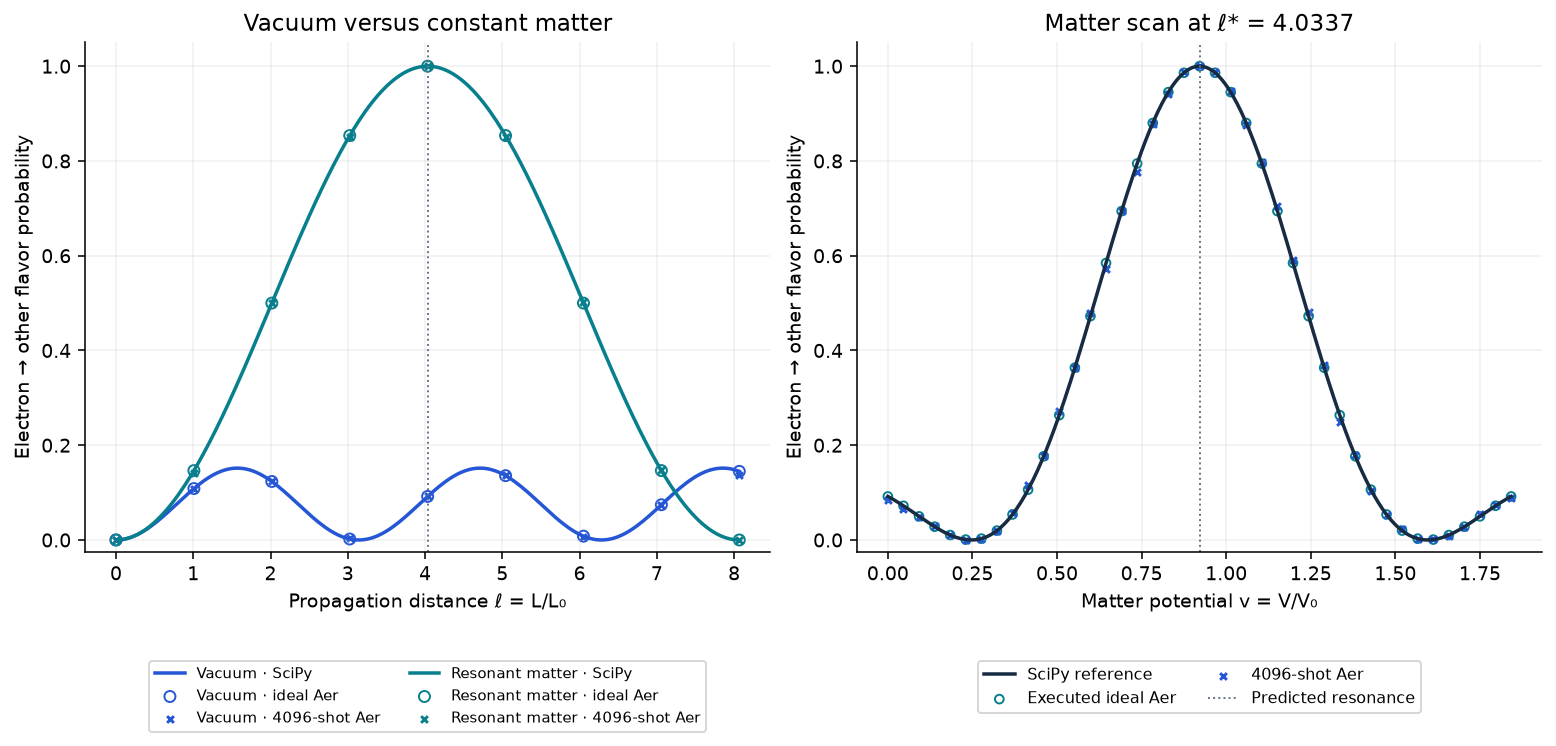

In [6]:
distance_curves = {}
for label, potential in [("Vacuum", 0.0), ("Resonant matter", resonance_potential)]:
    request = NeutrinoRequest(
        experiment=Experiment(parameters=parameters, layers=[Layer(distance=2 * resonant_distance, potential=potential)], shots=4096, seed=42),
        axis="distance", samples=41, timeout_seconds=60,
    )
    distance_curves[label] = run_curve(request)

density_request = NeutrinoRequest(experiment=resonant_case, axis="potential", samples=41, max_potential=2 * resonance_potential, timeout_seconds=60)
density_curve = run_curve(density_request)

all_curve_records = [record for curve in distance_curves.values() for record in curve.results] + list(density_curve.results)
for record in all_curve_records:
    assert record.simulated is True and record.backend == "aer_simulator"
    assert sum(record.counts.values()) == record.shots
    assert np.isclose(record.numerical.electron + record.numerical.other, 1.0, atol=1e-12)
    assert np.isclose(record.ideal.electron + record.ideal.other, 1.0, atol=1e-12)
    assert max(record.absolute_errors.ideal_vs_numerical.model_dump().values()) < 1e-12

figure, axes = plt.subplots(1, 2, figsize=(11, 5.2), layout="constrained")
distance_grid = np.linspace(0, 2 * resonant_distance, 201)
marker_indices = np.arange(0, 41, 5)
for label, potential, color in [("Vacuum", 0.0, BLUE), ("Resonant matter", resonance_potential, TEAL)]:
    reference = [probabilities(numerical(Experiment(parameters=parameters, layers=[Layer(distance=float(distance), potential=potential)])))["other"] for distance in distance_grid]
    axes[0].plot(distance_grid, reference, color=color, linewidth=1.8, label=f"{label} · SciPy")
    curve = distance_curves[label]
    axes[0].scatter(np.asarray(curve.coordinates)[marker_indices], [curve.results[index].ideal.other for index in marker_indices], s=32, facecolors="none", edgecolors=color, label=f"{label} · ideal Aer")
    axes[0].scatter(np.asarray(curve.coordinates)[marker_indices], [curve.results[index].measured.other for index in marker_indices], s=12, color=color, marker="x", label=f"{label} · 4096-shot Aer")
axes[0].axvline(resonant_distance, color="#64748b", linestyle=":", linewidth=1)
axes[0].set(xlabel="Propagation distance ℓ = L/L₀", ylabel="Electron → other flavor probability", title="Vacuum versus constant matter", ylim=(-0.025, 1.05))
axes[0].legend(fontsize=7.6, loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2)

potential_grid = np.linspace(0, 2 * resonance_potential, 301)
density_reference = [probabilities(numerical(Experiment(parameters=parameters, layers=[Layer(distance=resonant_distance, potential=float(potential))])))["other"] for potential in potential_grid]
axes[1].plot(potential_grid, density_reference, color="#172b43", linewidth=1.8, label="SciPy reference")
axes[1].scatter(density_curve.coordinates, [record.ideal.other for record in density_curve.results], s=20, facecolors="none", edgecolors=TEAL, label="Executed ideal Aer")
axes[1].scatter(density_curve.coordinates, [record.measured.other for record in density_curve.results], s=12, color=BLUE, marker="x", label="4096-shot Aer")
axes[1].axvline(resonance_potential, color="#64748b", linestyle=":", linewidth=1, label="Predicted resonance")
axes[1].set(xlabel="Matter potential v = V/V₀", ylabel="Electron → other flavor probability", title=f"Matter scan at ℓ* = {resonant_distance:.4f}", ylim=(-0.025, 1.05))
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2)
plt.show()

In [7]:
midpoint = 20
vacuum_at_baseline = distance_curves["Vacuum"].results[midpoint]
matter_at_baseline = distance_curves["Resonant matter"].results[midpoint]
display_table(["Environment at ℓ*", "SciPy P(other)", "Ideal Aer P(other)", "Measured P(other)", "Other counts / shots"], [
    [label, f"{record.numerical.other:.10f}", f"{record.ideal.other:.10f}", f"{record.measured.other:.10f}", f"{record.counts.get('1', 0)} / {record.shots}"]
    for label, record in [("Vacuum", vacuum_at_baseline), ("Resonant matter", matter_at_baseline)]
])
assert matter_at_baseline.numerical.other > vacuum_at_baseline.numerical.other
assert abs(matter_at_baseline.numerical.other - 1) < 1e-12
fresh_curve_max_error = max(max(record.absolute_errors.ideal_vs_numerical.model_dump().values()) for record in all_curve_records)
display(Markdown(f"At the selected baseline, the independent calculation gives conversion **{vacuum_at_baseline.numerical.other:.8f} in vacuum** and **{matter_at_baseline.numerical.other:.8f} in resonant matter**. Across all {len(all_curve_records)} fresh curve points, the largest ideal Aer versus SciPy flavor-probability discrepancy is **{fresh_curve_max_error:.3e}**. These executed values support the stated hypothesis for the chosen model and baseline."))

Environment at ℓ*,SciPy P(other),Ideal Aer P(other),Measured P(other),Other counts / shots
Vacuum,0.0918826821,0.0918826821,0.0920410156,377 / 4096
Resonant matter,1.0000000000,1.0000000000,1.0000000000,4096 / 4096


At the selected baseline, the independent calculation gives conversion **0.09188268 in vacuum** and **1.00000000 in resonant matter**. Across all 123 fresh curve points, the largest ideal Aer versus SciPy flavor-probability discrepancy is **1.221e-15**. These executed values support the stated hypothesis for the chosen model and baseline.

## 5. Numerical accuracy and controls

Probability agreement, state normalization and the full-unitary check test complementary aspects
of the implementation. We also execute zero-distance, ordered-layer and antineutrino controls.
The existing runner repeats each constant layer as two substeps to check numerical stability.
That test concerns constant-layer matrix arithmetic. Smooth-profile discretization would require
an additional model and convergence study.

The following table reports fresh runs. Its error column covers both modeled flavors.
Raw complex states, seeds, counts, analytical values and timing scopes are retained in the appendix.

In [8]:
control_cases = {
    "Vacuum": vacuum_case,
    "Resonant matter": resonant_case,
    "Off-resonance matter": Experiment(parameters=parameters, layers=[Layer(distance=resonant_distance, potential=2 * resonance_potential)], shots=4096, seed=42),
    "Ordered layers": Experiment(parameters=parameters, layers=[Layer(distance=0.5, potential=0.2), Layer(distance=0.5, potential=1.4)], shots=4096, seed=42),
    "Zero distance": Experiment(parameters=parameters, layers=[Layer(distance=0.0, potential=resonance_potential)], shots=4096, seed=42),
    "Antineutrino control": Experiment(parameters=parameters.model_copy(update={"particle": "antineutrino"}), layers=[Layer(distance=resonant_distance, potential=resonance_potential)], shots=4096, seed=42),
}
control_records = {label: run(case) for label, case in control_cases.items()}
control_rows = []
for label, record in control_records.items():
    probability_error = max(record["absolute_errors"]["ideal_vs_numerical"].values())
    assert probability_error < 1e-12
    assert abs(record["numerics"]["reference_norm"] - 1) < 1e-12
    assert abs(record["numerics"]["ideal_norm"] - 1) < 1e-12
    assert record["numerics"]["subdivision_check"]["state_change_l2"] < 1e-12
    assert sum(record["counts"].values()) == record["shots"]
    control_rows.append([label, f"{record['numerical']['other']:.8f}", f"{probability_error:.3e}", f"{record['numerics']['state_error_l2']:.3e}", record["circuit_depth"]])
assert control_records["Zero distance"]["ideal"]["electron"] == 1.0
display_table(["Executed control", "SciPy P(other)", "Max probability error", "State L² error", "Depth with measurement"], control_rows)

Executed control,SciPy P(other),Max probability error,State L² error,Depth with measurement
Vacuum,0.09188268,5.551e-16,2.722e-16,4
Resonant matter,1.00000000,5.305e-32,2.303e-16,4
Off-resonance matter,0.09188268,2.220e-16,1.927e-16,4
Ordered layers,0.13932588,2.220e-16,1.783e-16,7
Zero distance,0.00000000,0.000e+00,0.000e+00,1
Antineutrino control,0.03996672,3.331e-16,4.540e-16,4


## 6. Repeated finite-shot benchmarking

We reuse **Developer 3's existing benchmark runner**, which calls Nick's validated bounded
runner and preserves every response. The fixed nine-potential matter curve is repeated for
shot counts 256, 1024 and 4096, each with five distinct base seeds. Each curve increments its
base seed by point index. The same base-seed list is reused across shot counts.

We distinguish ideal-versus-SciPy numerical error, measured-versus-ideal sampling error and
measured-versus-SciPy total error. At a fixed probability $p$, the theoretical root-mean-square
sampling error is $\sqrt{p(1-p)/N}$. We compare this reference with the observed RMSE over five
seeds at the vacuum-potential endpoint. Small repeated samples provide descriptive evidence
and can show irregular changes as shots increase.

The suite uses a fresh worker for each curve and zero explicit warmup runs. Its wall timer
includes worker startup, validation and cleanup. Point-level SciPy and circuit timers cover
different workloads and can overlap their enclosing timers. Practical speedup remains
unestablished for this small, classically tractable model.

In [9]:
benchmark_plan = NeutrinoBenchmarkPlan(
    request=NeutrinoRequest(experiment=resonant_case, axis="potential", samples=9, max_potential=2 * resonance_potential, timeout_seconds=60),
    shot_counts=[256, 1024, 4096],
    seeds=[42, 142, 242, 342, 442],
    total_timeout_seconds=180,
)
benchmark_report = run_neutrino_benchmark(benchmark_plan)
assert benchmark_report.status == "completed"
assert len(benchmark_report.runs) == 15
assert all(len(item.response.results) == 9 for item in benchmark_report.runs)
benchmark_rows = []
sampling_summary = []
for shots in benchmark_plan.shot_counts:
    repetitions = [item for item in benchmark_report.runs if item.request.experiment.shots == shots]
    points = [item.response.results[0] for item in repetitions]
    target_probability = points[0].ideal.other
    errors = np.asarray([point.measured.other - point.ideal.other for point in points])
    rmse = float(np.sqrt(np.mean(errors**2)))
    standard_error = float(np.sqrt(target_probability * (1 - target_probability) / shots))
    minimum, maximum = float(np.min(abs(errors))), float(np.max(abs(errors)))
    sampling_summary.append({"shots": shots, "rmse": rmse, "minimum": minimum, "maximum": maximum, "theoretical_rmse": standard_error, "errors": errors.tolist()})
    benchmark_rows.append([shots, len(points), f"{rmse:.6f}", f"{minimum:.6f}", f"{maximum:.6f}", f"{standard_error:.6f}"])
display_table(["Shots", "Seeds at v=0", "Observed RMSE", "Min absolute error", "Max absolute error", "Bernoulli RMS reference"], benchmark_rows)
print(f"Executed {len(benchmark_report.runs)} curves and {sum(len(item.response.results) for item in benchmark_report.runs)} point records.")
print(f"Measured suite wall time {benchmark_report.elapsed_ms / 1000:.3f} seconds.")
print(benchmark_report.warmup_policy)

Shots,Seeds at v=0,Observed RMSE,Min absolute error,Max absolute error,Bernoulli RMS reference
256,5,0.025140,0.002039,0.044836,0.018054
1024,5,0.012674,0.000891,0.018469,0.009027
4096,5,0.005061,0.000086,0.008947,0.004513


Executed 15 curves and 135 point records.
Measured suite wall time 8.959 seconds.
fresh worker per curve with zero warmup runs


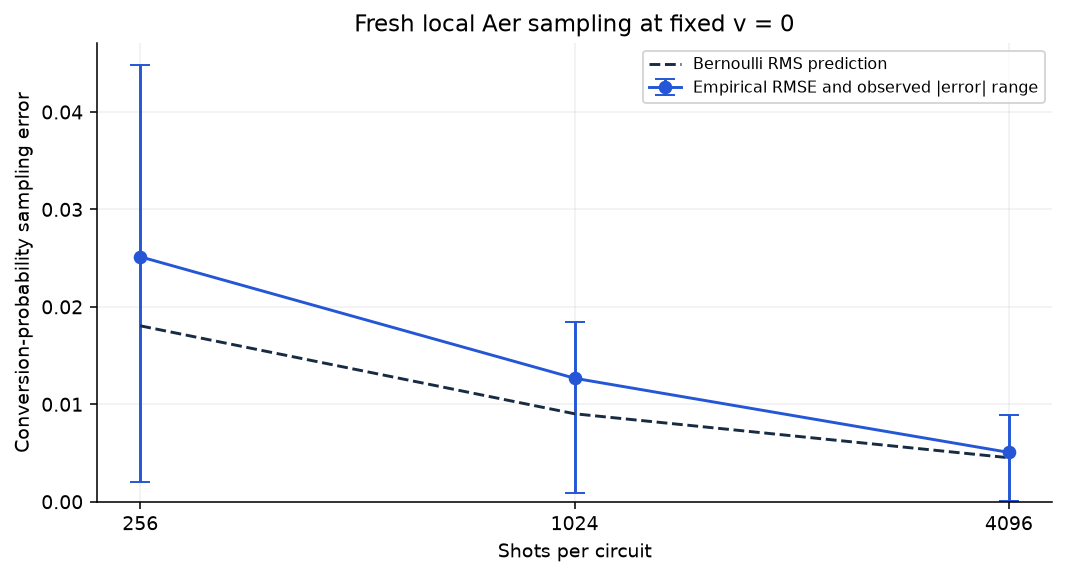

In [10]:
shot_grid = np.asarray([row["shots"] for row in sampling_summary])
empirical_rmse = np.asarray([row["rmse"] for row in sampling_summary])
minimum_errors = np.asarray([row["minimum"] for row in sampling_summary])
maximum_errors = np.asarray([row["maximum"] for row in sampling_summary])
figure, axis = plt.subplots(figsize=(7.5, 4), layout="constrained")
axis.errorbar(shot_grid, empirical_rmse, yerr=[empirical_rmse - minimum_errors, maximum_errors - empirical_rmse], color=BLUE, marker="o", capsize=5, label="Empirical RMSE and observed |error| range")
axis.plot(shot_grid, [row["theoretical_rmse"] for row in sampling_summary], color="#172b43", linestyle="--", label="Bernoulli RMS prediction")
axis.set_xscale("log", base=2)
axis.set_xticks(shot_grid, labels=[str(value) for value in shot_grid])
axis.set(xlabel="Shots per circuit", ylabel="Conversion-probability sampling error", title="Fresh local Aer sampling at fixed v = 0", ylim=(0, None))
axis.legend(fontsize=8)
plt.show()

The error bars above show the observed minimum and maximum absolute errors across five seeds.
They are descriptive ranges. The dashed line is a theoretical RMS sampling reference.
The benchmark preserves the individual errors and effective seeds so that a reader can
recompute every statistic. Increasing shots reduces the theoretical RMS error at fixed $p$,
while a particular finite collection of runs can fluctuate around that expectation.

## 7. Previously recorded IBM hardware measurements

The following data are **archived physical measurements collected on November 12, 2026**.
This notebook execution reads their frozen JSON and recomputes their comparisons and intervals.
Its execution performs fresh local simulation and analyzes the existing hardware record.

The original IBM job ran **all five Q-Atlas experiments in one shared submission**, retaining
separate measurements for each. We analyze its three neutrino circuits here. The complete
five-experiment record and the original provenance are embedded unchanged in this notebook.
The printed hashes identify those source bytes.

The original provenance reports a base Git revision with a dirty working tree and per-file
fingerprints. The present source snapshot has its own revision and SHA-256 manifest.
These records distinguish the original measurement provenance from this reproduction.

[Archived physical record](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/five-experiments.json),
[original provenance](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/provenance.json),
[team physical-results report](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/RESULTS.md)

In [11]:
hardware_job = json.loads((BUNDLE_ROOT / "evidence/five-experiments.json").read_text())
hardware_provenance = json.loads((BUNDLE_ROOT / "evidence/hardware-provenance.json").read_text())
assert hardware_job["status"] == "DONE" and hardware_job["measurement_complete"]
assert hardware_job["simulated"] is False
assert len(hardware_job["children"]) == 5
hardware_neutrinos = next(child for child in hardware_job["children"] if child["task"]["kind"] == "neutrinos")
hardware_request = NeutrinoRequest.model_validate(hardware_neutrinos["task"]["parameters"])
assert hardware_request.axis == "potential"
assert hardware_request.experiment.parameters == parameters
assert np.isclose(hardware_request.experiment.layers[0].distance, resonant_distance, atol=1e-12)
assert hardware_neutrinos["num_qubits"] == 1
assert all(child["job_id"] == hardware_job["job_id"] for child in hardware_job["children"])
total_circuits = sum(len(child["counts"]) for child in hardware_job["children"])
total_hardware_samples = sum(sum(counts.values()) for child in hardware_job["children"] for counts in child["counts"])
display_table(["Recorded provenance", "Value"], [
    ["Provider job", hardware_job["job_id"]],
    ["IBM device", hardware_job["backend_name"]],
    ["Original request UTC", hardware_job["created_at_utc"]],
    ["Experiments in shared job", ", ".join(child["task"]["kind"] for child in hardware_job["children"])],
    ["All-job circuits / total shots", f"{total_circuits} / {total_hardware_samples}"],
    ["Shots per circuit", hardware_neutrinos["shots"]],
    ["Neutrino logical qubits", hardware_neutrinos["num_qubits"]],
    ["Whole-job provider QPU usage (seconds)", hardware_job["timings"]["quantum_seconds"]],
    ["Original provenance base revision", hardware_provenance["revision"]],
    ["Original provenance dirty-tree flag", hardware_provenance["working_tree_dirty"]],
    ["Archived record SHA-256", BUNDLE_MANIFEST["evidence/five-experiments.json"]],
])

hardware_metrics = [metric for metric in hardware_neutrinos["metrics"] if metric["name"] == "other flavor probability"]
hardware_rows = []
hardware_comparisons = []
for index, metric in enumerate(hardware_metrics):
    counts = hardware_neutrinos["counts"][index]
    shots = hardware_neutrinos["shots"]
    assert set(counts).issubset({"0", "1"}) and sum(counts.values()) == shots
    successes = counts.get("1", 0)
    measured_probability = successes / shots
    case = Experiment(parameters=hardware_request.experiment.parameters, layers=[Layer(distance=hardware_request.experiment.layers[0].distance, potential=metric["coordinate"])])
    recomputed_reference = probabilities(numerical(case))["other"]
    assert abs(recomputed_reference - metric["classical"]) < 1e-12
    assert measured_probability == metric["quantum"]
    absolute_error = abs(measured_probability - recomputed_reference)
    assert abs(absolute_error - metric["absolute_error"]) < 1e-12
    interval = binomtest(successes, shots).proportion_ci(confidence_level=0.95, method="wilson")
    hardware_comparisons.append({"potential": metric["coordinate"], "successes": successes, "shots": shots, "measured": measured_probability, "classical": recomputed_reference, "absolute_error": absolute_error, "ci_low": interval.low, "ci_high": interval.high})
    hardware_rows.append([f"{metric['coordinate']:.9f}", f"{successes}/{shots}", f"{recomputed_reference:.9f}", f"{measured_probability:.9f}", f"{absolute_error:.9f}", f"[{interval.low:.6f}, {interval.high:.6f}]", hardware_neutrinos["circuit_depths"][index]])
display_table(["Potential v", "Other-flavor counts", "Recomputed SciPy", "Recorded IBM probability", "Absolute error", "95% Wilson interval", "Native depth"], hardware_rows)

Recorded provenance,Value
Provider job,dbr0sthabdes73fp2v60
IBM device,ibm_marrakesh
Original request UTC,2026-11-12T19:07:27.709952+00:00
Experiments in shared job,"compiler, optimization, search, materials, neutrinos"
All-job circuits / total shots,8 / 1024
Shots per circuit,128
Neutrino logical qubits,1
Whole-job provider QPU usage (seconds),2.0
Original provenance base revision,5786fd16913ae2a8d7089fb4abd581a4169790d9
Original provenance dirty-tree flag,True


Potential v,Other-flavor counts,Recomputed SciPy,Recorded IBM probability,Absolute error,95% Wilson interval,Native depth
0.000000000,15/128,0.091882682,0.117187500,0.025304818,"[0.072317, 0.184366]",6
0.921060994,126/128,1.000000000,0.984375000,0.015625000,"[0.944819, 0.995705]",2
1.842121988,15/128,0.091882682,0.117187500,0.025304818,"[0.072317, 0.184366]",6


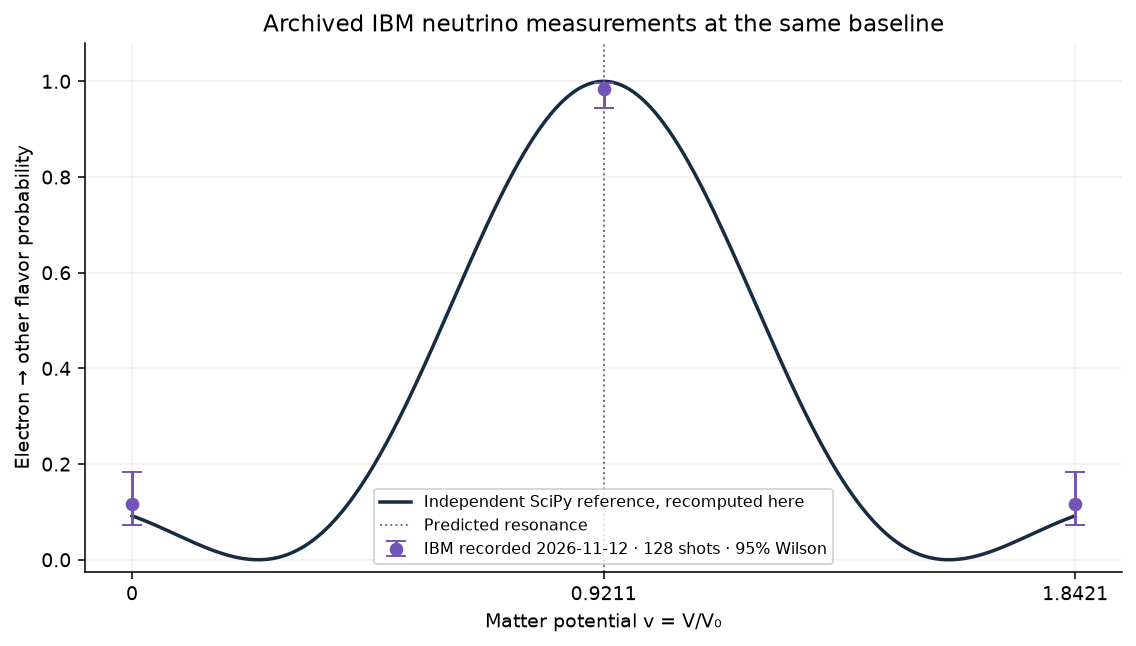

The archived resonance point records **126/128 converted outcomes**, or **0.984375**, compared with the recomputed classical prediction **1.000000**. Its absolute discrepancy is **0.015625**. The other two sampled potentials provide off-resonance controls.

In [12]:
recorded_probabilities = np.asarray([point["measured"] for point in hardware_comparisons])
interval_low = np.asarray([point["ci_low"] for point in hardware_comparisons])
interval_high = np.asarray([point["ci_high"] for point in hardware_comparisons])
figure, axis = plt.subplots(figsize=(8, 4.5), layout="constrained")
axis.plot(potential_grid, density_reference, color="#172b43", linewidth=1.8, label="Independent SciPy reference, recomputed here")
axis.errorbar([point["potential"] for point in hardware_comparisons], recorded_probabilities, yerr=[recorded_probabilities - interval_low, interval_high - recorded_probabilities], fmt="o", color=VIOLET, capsize=5, label="IBM recorded 2026-11-12 · 128 shots · 95% Wilson")
axis.axvline(resonance_potential, color="#64748b", linestyle=":", linewidth=1, label="Predicted resonance")
axis.set_xticks([0, resonance_potential, 2 * resonance_potential], labels=["0", f"{resonance_potential:.4f}", f"{2 * resonance_potential:.4f}"])
axis.set(xlabel="Matter potential v = V/V₀", ylabel="Electron → other flavor probability", title="Archived IBM neutrino measurements at the same baseline", ylim=(-0.025, 1.08))
axis.legend(fontsize=8, loc="lower center")
plt.show()

resonant_hardware_point = min(hardware_comparisons, key=lambda point: abs(point["potential"] - resonance_potential))
display(Markdown(f"The archived resonance point records **{resonant_hardware_point['successes']}/{resonant_hardware_point['shots']} converted outcomes**, or **{resonant_hardware_point['measured']:.6f}**, compared with the recomputed classical prediction **{resonant_hardware_point['classical']:.6f}**. Its absolute discrepancy is **{resonant_hardware_point['absolute_error']:.6f}**. The other two sampled potentials provide off-resonance controls."))

The Wilson intervals describe conditional binomial shot uncertainty for the recorded circuits.
Device bias, readout error, calibration drift and model uncertainty require additional analysis.
In particular, the resonance record includes two electron-flavor outcomes despite the ideal
unit conversion prediction. Its conditional interval lies below one. A single shared job supports
a small-device validation and motivates repeated hardware studies to investigate the discrepancy.

The recorded provider QPU usage covers the complete five-experiment job. Local preparation,
queue intervals, provider execution intervals and observed wall time have their original scopes
in the raw record. Those scopes can overlap. Independent per-experiment hardware wall times
remain unavailable. The executed local logical circuit and the archived native hardware circuits
use their respective compilation settings, so their reported depths have different contexts.
[Wilson interval implementation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html)

## 8. Conclusions, limitations and scientific impact

The executed comparisons connect the matter-enhanced conversion hypothesis to independent
classical evolution, exact one-qubit rotations, finite-shot local samples and a small set of
archived physical measurements. The numerical tolerance checks and raw records make that
connection auditable.

- **Model scope.** Two coherent effective flavors at fixed energy and prescribed matter provide
  a controlled benchmark. Three-flavor interference, CP phases, scattering, decoherence and
  interacting-neutrino transport require extended models and validation. The normalized parameter
  values are illustrative. A realistic solar or supernova prediction requires additional physics.
- **Quantum resources.** One flavor qubit and a constant number of rotations per constant layer
  keep this experiment small. Layer count increases propagation work without expanding the
  two-dimensional state space. Efficient classical 2×2 matrix evolution remains a strong baseline.
- **Sampling.** Five local seeds per shot count provide a descriptive sampling study. Reusing seeds
  across shot counts creates related groups. The archived physical data come from one shared job.
  Independent hardware repetitions and a calibrated noise analysis would strengthen inference.
- **Accuracy and timing.** Floating-point agreement validates the implemented circuit mapping.
  Sampling error and physical-device discrepancy answer additional questions. Classical reference
  evaluation and full circuit preparation/sampling perform different workloads. Practical quantum
  advantage remains unestablished by these measurements.
- **Impact.** The reproducible experiment makes the roles of mixing, matter and propagation phase
  visible, relates circuit resources to a defined physical model and exposes measurement uncertainty.
  It provides an educational and validation foundation for carefully specified future neutrino studies.

The contribution is an inspectable scientific workflow built around established physics and a
verified implementation. Predictions, numerical agreement and measurement limitations are
reported with their assumptions and source evidence.

## 9. Reproduction instructions and full executed evidence

1. Use Python 3.12. From an existing Q-Atlas checkout, the intended interpreter is
   `backend/.venv/bin/python` with its installed quantum dependencies.
2. Install notebook execution tools into that environment when needed.
   `uv pip install --python backend/.venv/bin/python nbformat nbclient ipykernel`
3. Open this notebook in a Jupyter-capable editor, select the backend Python interpreter,
   restart the kernel and run all cells from top to bottom. The source and archived evidence
   are embedded, so execution can also use an empty working directory with the same dependencies.
4. Reproduction should preserve the model, grids, seeds, shot counts and package versions printed
   above. Floating-point values and timing observations can vary with software and machine details.
   Physical-device counts remain identified as the immutable archived observation.

An existing repository environment can execute the notebook headlessly with the following code.
Run it with `backend/.venv/bin/python`. The kernel command explicitly selects that interpreter.

```python
import sys
from pathlib import Path
import nbformat
from jupyter_client import KernelManager
from nbclient import NotebookClient

path = Path("Q-Atlas_Quantum_for_Science.ipynb")
notebook = nbformat.read(path, as_version=4)
manager = KernelManager(kernel_name="python3")
manager.kernel_spec.argv = [sys.executable, "-m", "ipykernel_launcher", "-f", "{connection_file}"]
NotebookClient(notebook, km=manager, timeout=240).execute()
nbformat.write(notebook, path)
```

The next executed output retains complete fresh curve/control records, the benchmark plan and
all repetitions, the original five-experiment IBM job, its provenance and source fingerprints.
Tables above round values for reading. This structured output preserves measured precision.

In [13]:
full_evidence = {
    "notebook_source_revision": SOURCE_REVISION,
    "executed_at_utc": executed_at_utc,
    "software": software,
    "source_bundle_sha256": BUNDLE_SHA256,
    "embedded_file_sha256": BUNDLE_MANIFEST,
    "fresh_distance_curves": {label: curve.model_dump(mode="json") for label, curve in distance_curves.items()},
    "fresh_density_curve": density_curve.model_dump(mode="json"),
    "fresh_accuracy_controls": control_records,
    "fresh_benchmark": benchmark_report.model_dump(mode="json"),
    "recorded_hardware_job": hardware_job,
    "original_hardware_provenance": hardware_provenance,
    "recomputed_hardware_comparisons": hardware_comparisons,
}
serialized_evidence = json.dumps(full_evidence, allow_nan=False, sort_keys=True)
assert len(hardware_job["children"]) == 5
assert all(record["simulated"] for record in control_records.values())
assert all(point.simulated for item in benchmark_report.runs for point in item.response.results)
assert fresh_curve_max_error < 1e-12
display_table(["Validation", "Executed result"], [
    ["Fresh distance / density curve points", len(all_curve_records)],
    ["Additional accuracy controls", len(control_records)],
    ["Benchmark repetitions / point records", f"{len(benchmark_report.runs)} / {sum(len(item.response.results) for item in benchmark_report.runs)}"],
    ["Maximum fresh curve ideal-versus-SciPy probability error", f"{fresh_curve_max_error:.3e}"],
    ["Archived hardware experiments retained", len(hardware_job["children"])],
    ["Full evidence JSON size (bytes)", len(serialized_evidence.encode("utf-8"))],
    ["Full evidence SHA-256", hashlib.sha256(serialized_evidence.encode("utf-8")).hexdigest()],
])
display(JSON(full_evidence, expanded=False))

Validation,Executed result
Fresh distance / density curve points,123
Additional accuracy controls,6
Benchmark repetitions / point records,15 / 135
Maximum fresh curve ideal-versus-SciPy probability error,1.221e-15
Archived hardware experiments retained,5
Full evidence JSON size (bytes),974135
Full evidence SHA-256,826c14973543284b2cd9c97e5419c4a71c203d3cdf1f8568362f7b415a7c9f40


<IPython.core.display.JSON object>

## 10. Citations and source references

1. M. C. Gonzalez-Garcia and R. Wendell, *Neutrino Masses, Mixing, and Oscillations*,
   Particle Data Group, revised August 2025, Sections 14.4–14.5.
   [Official review](https://pdg.lbl.gov/2025/reviews/rpp2025-rev-neutrino-mixing.pdf)
2. IBM Quantum, Qiskit `RYGate` API documentation, rotation convention.
   [Official documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RYGate)
3. SciPy, `scipy.linalg.expm`, independent matrix-exponential implementation.
   [Official documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.expm.html)
4. SciPy, `BinomTestResult.proportion_ci`, Wilson intervals without continuity correction.
   [Official documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html)
5. Q-Atlas team, *Final Science Report* and *Q-Neutrino* conventions.
   [Final report](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/FINAL_SCIENCE_REPORT.md),
   [physics and units](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/NEUTRINOS.md),
   [challenge answers](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/SCIENCE_CHALLENGE_ANSWERS.md)
6. Q-Atlas team, verified implementation and Developer 3's repeated-run method.
   [Neutrino source](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/backend/app/experiments/neutrinos),
   [benchmark implementation](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/backend/app/benchmarks/neutrinos.py),
   [benchmark methodology](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/NEUTRINO_BENCHMARKING.md)
7. Q-Atlas team, archived physical IBM evidence, November 12, 2026, job
   `dbr0sthabdes73fp2v60` on `ibm_marrakesh`.
   [Raw record](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/five-experiments.json),
   [provenance](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/provenance.json),
   [results report](https://github.com/Kent-Brogrammers/Q-Atlas/blob/1a62e1d3f933f5111e28a1750cbfd36546c2834d/docs/evidence/ibm-qpu-2026-11-12/RESULTS.md)

The challenge's reporting themes are credited to Anthony Yuhos and Aatmaj Rajesh,
*Quantum Computing for Science*, Ohio State Qiskit Fall Fest 2026, as acknowledged
in the team's science reports. This submission's text, executed experiment and figures were
assembled for Q-Atlas. The implementation and archived evidence are attributed to the Q-Atlas team.